In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q kagglehub

from google.colab import userdata
import os

os.environ["KAGGLE_API_KEY"] = userdata.get("KAGGLE_API_KEY")

In [20]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import kagglehub

path = kagglehub.dataset_download(
    "dataclusterlabs/potholes-or-cracks-on-road-image-dataset",
    output_dir="/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle_CH"
)

print(path)

Mounted at /content/drive
Using Colab cache for faster access to the 'potholes-or-cracks-on-road-image-dataset' dataset.
/kaggle/input/potholes-or-cracks-on-road-image-dataset


In [ ]:
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)

    if level > 3:
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

potholes-or-cracks-on-road-image-dataset/
  pothole_icon.jpg
  dataset/
    potholes batçh 1/
      20220819_15_31_59_009_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.jpg
      20220819_18_06_49_994_000_NICf9pZpG7Wd4tmRH1tzGvEfPNn1_F_3000_4000.jpg
      20220819_15_33_56_310_000_hnEYwZk1I5RsPJ0KVT40Wir0BSh1_F_4160_3120.xml
      20220817_17_56_37_846_000_bRdv1ZdJyuNZ1KHjHqI2DLGVsz22_F_3000_4000.xml
      20220817_08_12_40_336_000_TRIhBb1cEeebPUftMdWRoZiypzD2_F_4080_3072.jpg


In [ ]:
import os
import shutil
import random
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
import yaml

# ==========================================
# 1. PATHS
# ==========================================

DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/dataset"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO"
)

random.seed(42)

# ==========================================
# 2. FIND XML FILES AND MATCH IMAGES
# ==========================================

image_extensions = [".jpg", ".jpeg", ".png"]

annotations = []

for xml_file in DATASET_DIR.rglob("*.xml"):

    try:
        root = ET.parse(xml_file).getroot()

        filename = root.findtext("filename")

        image_path = None

        # First try the filename specified in XML
        if filename:
            candidate = xml_file.parent / Path(filename).name

            if candidate.exists():
                image_path = candidate

        # Fallback: find image with matching stem
        if image_path is None:
            for ext in image_extensions:
                candidate = xml_file.with_suffix(ext)

                if candidate.exists():
                    image_path = candidate
                    break

        if image_path is not None:
            annotations.append((image_path, xml_file))

    except Exception as e:
        print("Invalid XML:", xml_file, e)

print("Matched image-annotation pairs:", len(annotations))

# ==========================================
# 3. EXTRACT ALL CLASS NAMES
# ==========================================

all_classes = set()

for image_path, xml_file in annotations:

    root = ET.parse(xml_file).getroot()

    for obj in root.findall("object"):

        class_name = obj.findtext("name")

        if class_name:
            all_classes.add(class_name.strip())

classes = sorted(all_classes)

class_to_id = {
    name: i for i, name in enumerate(classes)
}

print("\nClasses found:")

for name, class_id in class_to_id.items():
    print(class_id, ":", name)

# ==========================================
# 4. CREATE YOLO FOLDER STRUCTURE
# ==========================================

for split in ["train", "val", "test"]:

    (OUTPUT_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (OUTPUT_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# ==========================================
# 5. SPLIT DATASET
# ==========================================

random.shuffle(annotations)

total = len(annotations)

train_end = int(total * 0.8)
val_end = int(total * 0.9)

splits = {
    "train": annotations[:train_end],
    "val": annotations[train_end:val_end],
    "test": annotations[val_end:]
}

# ==========================================
# 6. CONVERT VOC XML TO YOLO TXT
# ==========================================

image_counts = Counter()
instance_counts = Counter()

from PIL import Image

for split, files in splits.items():

    for image_path, xml_file in files:

        root = ET.parse(xml_file).getroot()

        # Unique filename to avoid collisions
        unique_name = (
            str(image_path.relative_to(DATASET_DIR))
            .replace("\\", "_")
            .replace("/", "_")
        )

        image_name = Path(unique_name).name

        # Copy image
        destination_image = (
            OUTPUT_DIR / "images" / split / image_name
        )

        shutil.copy2(image_path, destination_image)

        # Get actual image dimensions
        with Image.open(image_path) as img:
            img_width, img_height = img.size

        yolo_annotations = []
        image_classes = set()

        for obj in root.findall("object"):

            class_name = obj.findtext("name")

            if not class_name:
                continue

            class_name = class_name.strip()

            bbox = obj.find("bndbox")

            if bbox is None:
                continue

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            # Validate bounding box
            if not (
                0 <= xmin < xmax <= img_width
                and 0 <= ymin < ymax <= img_height
            ):
                continue

            # Pascal VOC -> YOLO
            x_center = ((xmin + xmax) / 2) / img_width
            y_center = ((ymin + ymax) / 2) / img_height

            width = (xmax - xmin) / img_width
            height = (ymax - ymin) / img_height

            class_id = class_to_id[class_name]

            yolo_annotations.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

            instance_counts[class_name] += 1
            image_classes.add(class_name)

        # Save YOLO TXT
        label_name = Path(image_name).with_suffix(".txt")

        label_path = (
            OUTPUT_DIR / "labels" / split / label_name
        )

        with open(label_path, "w") as f:
            f.write("\n".join(yolo_annotations))

        for class_name in image_classes:
            image_counts[class_name] += 1

    print(f"{split}: {len(files)} images processed")

# ==========================================
# 7. GENERATE data.yaml
# ==========================================

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(classes),
    "names": classes
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# ==========================================
# 8. DISPLAY STATISTICS
# ==========================================

print("\n========== CONVERSION COMPLETE ==========")

print("Total images:", total)
print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("Testing images:", len(splits["test"]))

print("\nClass statistics:")

for class_name in classes:
    print(
        f"{class_name}: "
        f"{instance_counts[class_name]} instances, "
        f"{image_counts[class_name]} images"
    )

print("\nYOLO dataset saved at:", OUTPUT_DIR)

Matched image-annotation pairs: 0

Classes found:
train: 0 images processed
val: 0 images processed
test: 0 images processed

========== CONVERSION COMPLETE ==========
Total images: 0
Training images: 0
Validation images: 0
Testing images: 0

Class statistics:

YOLO dataset saved at: /content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO


In [ ]:
print("data.yaml:")
print((OUTPUT_DIR / "data.yaml").read_text())

print("\nSample YOLO annotation:")

label_files = list((OUTPUT_DIR / "labels/train").glob("*.txt"))

if label_files:
    print(label_files[0].read_text())

data.yaml:
path: /content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO
train: images/train
val: images/val
test: images/test
nc: 2
names:
- potholes
- w


Sample YOLO annotation:
0 0.444391 0.266827 0.305449 0.086538
0 0.843429 0.383053 0.313141 0.084856
0 0.397436 0.164303 0.181410 0.044952
0 0.273397 0.105769 0.044872 0.033654
0 0.071635 0.074519 0.055449 0.019231
0 0.032051 0.097716 0.044872 0.017548
0 0.017788 0.121755 0.034936 0.027163
0 0.020994 0.152163 0.041346 0.033654
0 0.034936 0.353365 0.069231 0.099519
0 0.216827 0.079327 0.021474 0.025481


In [ ]:
!pip install -q ultralytics matplotlib pyyaml pandas

In [ ]:
from ultralytics.data.utils import check_det_dataset
from ultralytics.utils.plotting import plot_labels

data = check_det_dataset(str(OUTPUT_DIR / "data.yaml"))

print(data)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{'path': PosixPath('/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO'), 'train': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/images/train', 'val': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/images/val', 'test': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/images/test', 'nc': 2, 'names': {0: 'potholes', 1: 'w'}, 'yaml_file': '/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/data.yaml', 'channels': 3}


Total annotations: 514
Total classes: 2


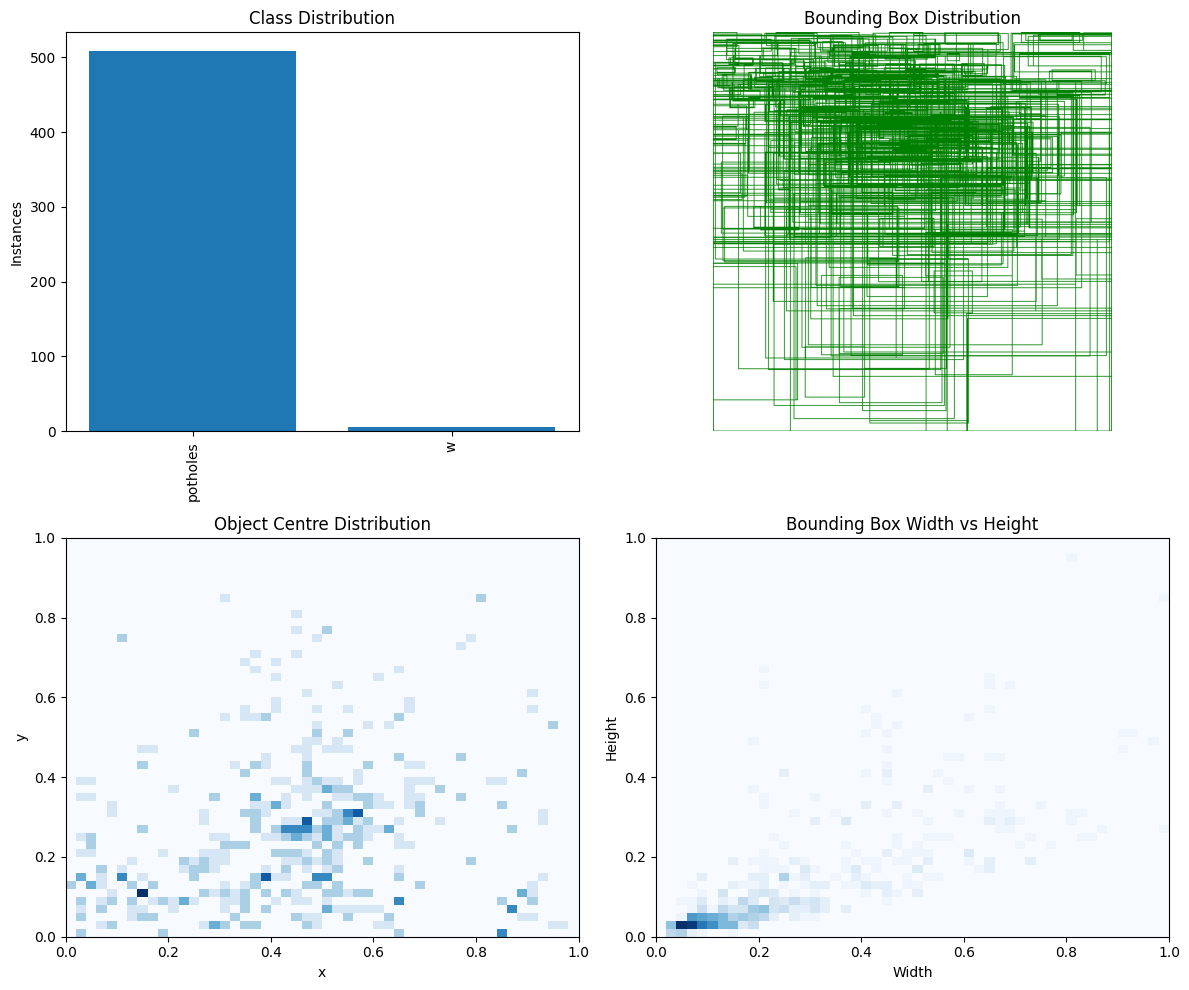

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO/dataset_analysis.jpg


In [ ]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO"
)

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = Path(config.get("path", DATASET_DIR))

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)

In [21]:
import glob, os, random, hashlib
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# ---------- settings ----------
ROOT = "/content/drive/MyDrive/Hazard_Detection/raw_datasets/potholes_kaggle/YOLO"
SPLITS = ["train", "val", "test"]     # change if your folders are named differently
NUM_CLASSES = 1                       # pothole only
IMG_EXTS = {".jpg", ".jpeg", ".png"}
TINY_PX = 16          # boxes narrower or shorter than this (in original pixels) are flagged
HUGE_FRAC = 0.5       # boxes covering more than this share of the image are flagged
MAX_ASPECT = 6        # width/height ratio beyond this (either way) is flagged
DUP_IOU = 0.9         # two boxes in one image overlapping this much are flagged
EDGE_TOL = 0.01       # allowed overshoot past the image edge (normalised)
SEED = 51
OUT = Path(ROOT) / "bbox_report"
OUT.mkdir(exist_ok=True)
random.seed(SEED)

# ---------- helpers ----------
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

def md5(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

def find_images(split):
    d = Path(ROOT, "images", split)
    return {p.stem: p for p in d.iterdir() if p.suffix.lower() in IMG_EXTS} if d.exists() else {}

# ---------- collect every box ----------
box_rows, image_rows, format_problems = [], [], []

for split in SPLITS:
    imgs = find_images(split)
    labels = sorted(Path(ROOT, "labels", split).glob("*.txt"))

    # labels with no matching image, and images with no label file
    label_stems = {l.stem for l in labels}
    for stem in set(imgs) - label_stems:
        format_problems.append({"split": split, "file": imgs[stem].name, "problem": "image has no label file"})
    for l in labels:
        if l.stem not in imgs:
            format_problems.append({"split": split, "file": l.name, "problem": "label has no image"})

    for lf in labels:
        img_path = imgs.get(lf.stem)
        img_w = img_h = None
        if img_path is not None:
            with Image.open(img_path) as im:
                img_w, img_h = im.size
        boxes_here = []
        for ln, line in enumerate(lf.read_text().splitlines(), 1):
            if not line.strip():
                continue
            p = line.split()
            if len(p) != 5:
                format_problems.append({"split": split, "file": lf.name, "problem": f"line {ln}: {len(p)} fields"})
                continue
            try:
                cls, xc, yc, w, h = int(float(p[0])), *map(float, p[1:])
            except ValueError:
                format_problems.append({"split": split, "file": lf.name, "problem": f"line {ln}: not numeric"})
                continue
            boxes_here.append((cls, xc, yc, w, h))

        image_rows.append({"split": split, "file": lf.stem, "n_boxes": len(boxes_here),
                           "img_w": img_w, "img_h": img_h,
                           "md5": md5(img_path) if img_path else None})

        for cls, xc, yc, w, h in boxes_here:
            x1, y1, x2, y2 = xc - w/2, yc - h/2, xc + w/2, yc + h/2
            px_w = w * img_w if img_w else np.nan
            px_h = h * img_h if img_h else np.nan
            aspect = w / h if h > 0 else np.inf
            issues = []
            if cls < 0 or cls >= NUM_CLASSES:
                issues.append("class id out of range")
            if w <= 0 or h <= 0:
                issues.append("zero or negative size")
            if x1 < -EDGE_TOL or y1 < -EDGE_TOL or x2 > 1+EDGE_TOL or y2 > 1+EDGE_TOL:
                issues.append("extends past image edge")
            if img_w and (px_w < TINY_PX or px_h < TINY_PX):
                issues.append("tiny box")
            if w * h > HUGE_FRAC:
                issues.append("covers most of image")
            if aspect > MAX_ASPECT or aspect < 1/MAX_ASPECT:
                issues.append("extreme aspect ratio")
            box_rows.append({"split": split, "file": lf.stem, "cls": cls,
                             "xc": xc, "yc": yc, "w": w, "h": h,
                             "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                             "px_w": px_w, "px_h": px_h, "area_frac": w*h,
                             "aspect": aspect, "issues": "; ".join(issues)})

boxes = pd.DataFrame(box_rows)
images = pd.DataFrame(image_rows)
problems = pd.DataFrame(format_problems)

# ---------- within-image duplicates ----------
dup_rows = []
for (split, f), g in boxes.groupby(["split", "file"]):
    xy = g[["x1", "y1", "x2", "y2"]].values
    idx = g.index.tolist()
    for i in range(len(idx)):
        for j in range(i+1, len(idx)):
            if iou(xy[i], xy[j]) > DUP_IOU:
                dup_rows.append({"split": split, "file": f, "box_a": idx[i], "box_b": idx[j]})
dups = pd.DataFrame(dup_rows)
if len(dups):
    boxes.loc[dups["box_b"].unique(), "issues"] = boxes.loc[dups["box_b"].unique(), "issues"] \
        .apply(lambda s: (s + "; " if s else "") + "duplicate box in image")

# ---------- identical images across the whole dataset ----------
hash_groups = images.dropna(subset=["md5"]).groupby("md5")
same_image = [g[["split", "file"]].values.tolist() for _, g in hash_groups if len(g) > 1]

# ---------- summary ----------
print("=" * 60)
print(f"Images with labels: {len(images)} | boxes: {len(boxes)}")
print("Boxes per split:", boxes["split"].value_counts().to_dict())
print(f"Format problems: {len(problems)}")
print(f"Images with no boxes (negatives): {(images['n_boxes'] == 0).sum()}")
print(f"Within-image duplicate pairs: {len(dups)}")
print(f"Exact-duplicate image groups: {len(same_image)}")
if same_image:
    cross = sum(1 for grp in same_image if len({s for s, _ in grp}) > 1)
    print(f"  of which span more than one split (leakage): {cross}")

print("\nBox size (normalised), percentiles 5 / 25 / 50 / 75 / 95:")
for col in ["w", "h", "area_frac"]:
    print(f"  {col:10s}", np.round(boxes[col].quantile([.05, .25, .5, .75, .95]).values, 4))
if boxes["px_w"].notna().any():
    print("Box size (pixels), percentiles 5 / 50 / 95:")
    for col in ["px_w", "px_h"]:
        print(f"  {col:10s}", np.round(boxes[col].quantile([.05, .5, .95]).values, 1))

print("\nIssue counts (a box can have several):")
issue_counts = Counter(i.strip() for s in boxes["issues"] for i in s.split(";") if i.strip())
for k, v in issue_counts.most_common():
    print(f"  {k:28s} {v}")
print(f"Boxes with no issues: {(boxes['issues'] == '').sum()} of {len(boxes)}")

print("\nBoxes per image:", boxes.groupby(["split", "file"]).size().describe().round(2).to_dict())

if len(problems):
    print("\nFirst format problems:")
    print(problems.head(10).to_string(index=False))

# ---------- save reports ----------
boxes.to_csv(OUT / "all_boxes.csv", index=False)
boxes[boxes["issues"] != ""].to_csv(OUT / "flagged_boxes.csv", index=False)
problems.to_csv(OUT / "format_problems.csv", index=False)
images.to_csv(OUT / "images.csv", index=False)
print(f"\nReports saved in {OUT}")

# ---------- visual check ----------
def draw_sample(rows, title, path):
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        img_path = find_images(r["split"]).get(r["file"])
        if img_path is None:
            ax.axis("off"); continue
        im = Image.open(img_path).convert("RGB")
        d = ImageDraw.Draw(im)
        W, H = im.size
        for _, b in boxes[(boxes["split"] == r["split"]) & (boxes["file"] == r["file"])].iterrows():
            color = "red" if b["issues"] else "lime"
            d.rectangle([b["x1"]*W, b["y1"]*H, b["x2"]*W, b["y2"]*H], outline=color, width=3)
        ax.imshow(im)
        ax.set_title(f"{r['split']}/{r['file']}\n{r['issues'][:60]}", fontsize=8)
        ax.axis("off")
    for ax in axes.ravel()[len(rows):]:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=110)
    plt.show()

random_boxes = boxes.sample(min(6, len(boxes)), random_state=SEED)
draw_sample(random_boxes, "Random boxes (green = no issue, red = flagged)", OUT / "sample_random.png")

if (boxes["issues"] != "").any():
    flagged = boxes[boxes["issues"] != ""].sample(min(6, (boxes["issues"] != "").sum()), random_state=SEED)
    draw_sample(flagged, "Flagged boxes", OUT / "sample_flagged.png")

Output hidden; open in https://colab.research.google.com to view.